# Exercício 2017 · Uma estação chuvosa normal ★
**VERSÃO DOS FACILITADORES (com soluções)**

Em 2017 o pico do Incomáti foi de 310 m³/s (1 de março de 2017), **abaixo** do limite de alerta laranja (376 m³/s). A imagem da estação chuvosa é de 8 de março de 2017 (215 m³/s). Satélite: **Landsat 8**.

| | Época seca | Estação chuvosa |
| --- | --- | --- |
| Data da imagem | 15 de outubro de 2016 | 8 de março de 2017 |
| Caudal nesse dia | 0,0 m³/s | 215 m³/s |
| Satélite | Landsat 8 | Landsat 8 |

Pico do caudal neste ano hidrológico: **310 m³/s a 1 de março de 2017** (modelo GloFAS).
Limites de alerta do ETE: laranja 376 m³/s, vermelho 970 m³/s.

**A vossa missão:** descobrir quanta água nova apareceu na planície de Marracuene nesta estação chuvosa,
fazer o mapa e explicar o resultado. Os passos são os mesmos do notebook guiado de 2026.

**Dificuldade:** ★ (★ directo, ★★ precisa de interpretação, ★★★ tem uma armadilha para investigar)


| Sinal | Quer dizer |
| --- | --- |
| ▶️ | Corra a célula: clique nela e prima **Shift + Enter** |
| ✏️ | Edite: troque os `...` pela sua resposta e corra outra vez |
| ✍️ | Responda por escrito, na célula de texto logo abaixo (duplo clique para escrever) |
| ✅ | A célula verifica a sua resposta |

## Passo 0 · Ferramentas ▶️

Corra as duas células seguintes sem mudar nada.

In [1]:
# Célula 0 · ferramentas da aula: corra sem mudar nada ▶️
import os                          # os: trabalhar com pastas e ficheiros
import glob                        # glob: procurar ficheiros pelo nome
import numpy as np                 # numpy: contas com tabelas de números (uma imagem é uma tabela)
import matplotlib.pyplot as plt    # matplotlib: desenhar imagens e gráficos

BANDAS = ["azul", "verde", "vermelho", "nir", "swir"]


def encontrar(nome):
    """Procura um ficheiro de dados: ao lado do notebook, na pasta dados/, no Colab e no Google Drive."""
    for sitio in [nome, os.path.join("dados", nome), "/content/" + nome, "/content/dados/" + nome]:
        if os.path.exists(sitio):
            return sitio
    no_colab = os.getcwd().startswith("/content")
    bases = ["/content/drive/MyDrive"] if no_colab else [".", "..", "../.."]
    for base in bases:
        achados = glob.glob(os.path.join(base, "**", nome), recursive=True)
        if achados:
            return achados[0]
    try:
        from google.colab import files            # só existe no Google Colab
        print("Não encontrei", nome, "- escolha esse ficheiro no seu computador:")
        files.upload()
        if os.path.exists(nome):
            return nome
    except ImportError:
        pass
    raise FileNotFoundError(f"Não encontrei {nome}. Coloque-o na pasta 'dados' ao lado deste notebook.")


def carregar(nome):
    """Abre um ficheiro .npz e devolve um dicionário com as bandas em reflectância (0 a 1)."""
    z = np.load(encontrar(nome))
    img = {banda: z[banda] / 10000 for banda in BANDAS}   # guardámos números inteiros: dividir por 10 000
    img["nuvem"] = z["nuvem"]       # True onde há nuvem, sombra ou falta de dados
    img["zona"] = z["zona"]         # True dentro do distrito de Marracuene e fora do mar
    for chave in ["data", "satelite", "epoca", "data_pico"]:
        img[chave] = str(z[chave])
    for chave in ["caudal_m3s", "caudal_pico_m3s", "resolucao_m"]:
        img[chave] = float(z[chave])
    return img


def cor_natural(img, brilho=0.15):
    """Junta vermelho, verde e azul numa imagem a cores, como a veríamos de um avião."""
    rgb = np.dstack([img["vermelho"], img["verde"], img["azul"]])
    return np.clip(rgb / brilho, 0, 1)


def falsa_cor(img, brilho=0.35):
    """NIR no canal vermelho: a vegetação fica vermelha e a água fica quase preta."""
    rgb = np.dstack([img["nir"], img["vermelho"], img["verde"]])
    return np.clip(rgb / brilho, 0, 1)


print("Ferramentas prontas.")

Ferramentas prontas.


In [2]:
# Célula 0b · verificador de respostas: corra sem mudar nada ▶️
import base64, json
_RESPOSTAS = json.loads(base64.b64decode("eyJhcmVhX3BpeGVsX2hhIjogWzAuMDksIDAuMDAwNSwgIlVtIHDDrXhlbCB0ZW0gMzAgbSB4IDMwIG0gPSA5MDAgbcKyLiBEaXZpZGEgb3MgbcKyIHBvciAxMCAwMDAuIl0sICJudXZlbV9wY3QiOiBbMTYuNiwgMC42LCAiVXNlIDEwMCAqIGNodXZvc2FbXCJudXZlbVwiXVt6b25hXS5tZWFuKCk6IGEgbcOpZGlhIGRlIFRydWUvRmFsc2Ugw6kgYSBmcmFjw6fDo28gZGUgVHJ1ZS4iXSwgImFndWFfc2VjYV9oYSI6IFsxMjE5LCAxMi4xOSwgIkNvbnRlIG9zIFRydWUgZGUgYWd1YV9zZWNhIGNvbSAuc3VtKCkgZSBtdWx0aXBsaXF1ZSBwb3IgYXJlYV9waXhlbF9oYSAoZSB1c2UgTElNSUFSID0gMCkuIl0sICJhZ3VhX2NodXZvc2FfaGEiOiBbODg3LCA4Ljg3MDAwMDAwMDAwMDAwMSwgIkNvbnRlIG9zIFRydWUgZGUgYWd1YV9jaHV2b3NhIGNvbSAuc3VtKCkgZSBtdWx0aXBsaXF1ZSBwb3IgYXJlYV9waXhlbF9oYSAoTElNSUFSID0gMCkuIl0sICJhZ3VhX25vdmFfaGEiOiBbNDMsIDUuMCwgIkNvbnRlIG9zIFRydWUgZGUgbm92YSBjb20gLnN1bSgpIGUgbXVsdGlwbGlxdWUgcG9yIGFyZWFfcGl4ZWxfaGEgKExJTUlBUiA9IDApLiJdfQ==").decode())


def verificar(chave, valor):
    """Compara a sua resposta com a de referência, com uma pequena margem."""
    if valor is ...:
        print("✏️ Ainda falta preencher esta resposta (troque os ... por uma conta).")
        return False
    referencia, margem, dica = _RESPOSTAS[chave]
    if abs(float(valor) - referencia) <= margem:
        print(f"✅ Certo! {chave} = {float(valor):.2f}")
        return True
    print(f"❌ Ainda não ({chave} = {float(valor):.2f}). Dica: {dica}")
    return False


def preenchido(*valores):
    """Pára com uma mensagem simples se ainda houver ... por preencher numa célula anterior."""
    assert all(v is not ... for v in valores), "✏️ Volte à célula anterior e troque os ... pela sua resposta."


print("Verificador pronto.")

Verificador pronto.


## Passo 1 · Pensar antes de programar ✍️

1. Que satélite tirou estas imagens? Nesta aula, cada píxel tem 30 m × 30 m. Quantos hectares tem um píxel?
2. **Previsão:** olhe para o caudal no dia da imagem e para o pico do ano. Espera ver uma cheia na planície?
   Muita ou pouca água nova? Escreva a sua previsão **antes** de calcular.

**Resposta-modelo (facilitadores):** Landsat 8. Um píxel = 30 x 30 = 900 m² = 0,09 ha. Previsão: comparar o caudal no dia da imagem (215 m³/s) e o pico (310 m³/s) com os limites 376 e 970 m³/s.

In [3]:
# ✏️ Quantos hectares tem um píxel de 30 m x 30 m? (1 ha = 10 000 m²)
area_pixel_ha = 30 * 30 / 10000
verificar("area_pixel_ha", area_pixel_ha)

✅ Certo! area_pixel_ha = 0.09


True

## Passo 2 · Abrir e ver as imagens ▶️

In [4]:
seca = carregar("incomati_2017_seca.npz")
chuvosa = carregar("incomati_2017_chuvosa.npz")
zona = seca["zona"]                   # distrito de Marracuene, sem o mar

for img in [seca, chuvosa]:
    print(f"{img['epoca']:8s} {img['data']}  {img['satelite']}  caudal {img['caudal_m3s']:.0f} m³/s")
print("Tamanho:", seca["verde"].shape, "píxeis")

seca     2016-10-15  Landsat 8  caudal 0 m³/s
chuvosa  2017-03-08  Landsat 8  caudal 215 m³/s
Tamanho: (1110, 735) píxeis


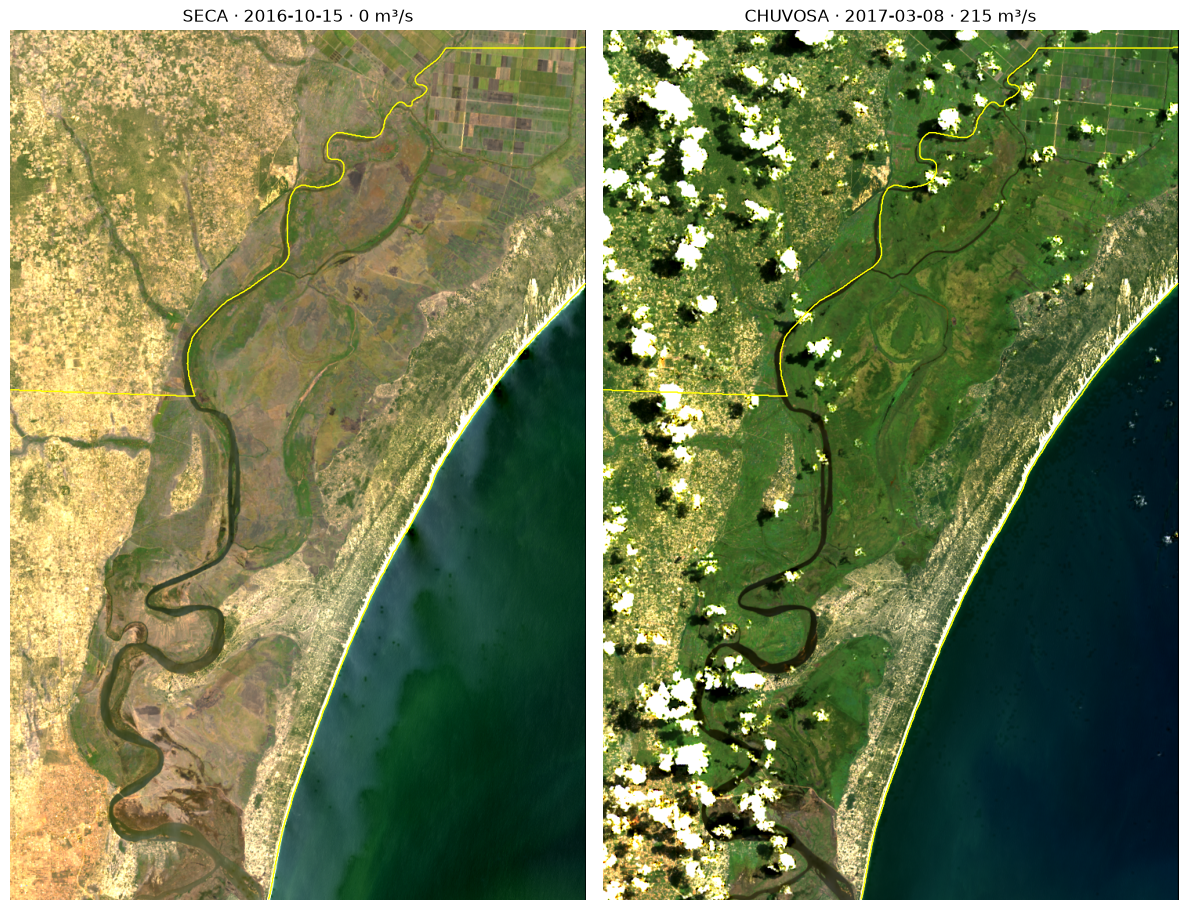

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 9))
for eixo, img in zip(eixos, [seca, chuvosa]):
    eixo.imshow(cor_natural(img))
    eixo.contour(zona, levels=[0.5], colors="yellow", linewidths=1)
    eixo.set_title(f"{img['epoca'].upper()} · {img['data']} · {img['caudal_m3s']:.0f} m³/s")
    eixo.axis("off")
plt.tight_layout()
plt.show()

✍️ **Pergunta:** o que mudou entre as duas imagens? Há nuvens? De que cor é a água?

**Resposta-modelo (facilitadores):** Comparar a largura do rio, as manchas de água na planície, a cor da água (castanha = sedimentos) e as nuvens (manchas brancas) e as suas sombras.

### ✏️ Quanta zona está tapada por nuvens?

`chuvosa["nuvem"][zona]` dá só os valores de nuvem **dentro da zona** (True ou False).
A média de True/False é a fracção de True. Multiplique por 100 para ter a percentagem.

In [6]:
nuvem_pct = 100 * chuvosa["nuvem"][zona].mean()     # ✏️
verificar("nuvem_pct", nuvem_pct)

✅ Certo! nuvem_pct = 16.57


True

## Passo 3 · Os índices de água ✏️

O NDWI já está feito. **Escreva o MNDWI** para as duas datas, seguindo o exemplo:

MNDWI = (Verde − SWIR) / (Verde + SWIR)

In [7]:
with np.errstate(divide="ignore", invalid="ignore"):
    ndwi_seca     = (seca["verde"] - seca["nir"]) / (seca["verde"] + seca["nir"])
    ndwi_chuvosa  = (chuvosa["verde"] - chuvosa["nir"]) / (chuvosa["verde"] + chuvosa["nir"])
    mndwi_seca    = (seca["verde"] - seca["swir"]) / (seca["verde"] + seca["swir"])       # ✏️
    mndwi_chuvosa = (chuvosa["verde"] - chuvosa["swir"]) / (chuvosa["verde"] + chuvosa["swir"])    # ✏️

preenchido(mndwi_seca, mndwi_chuvosa)
print("Índices calculados.")

Índices calculados.


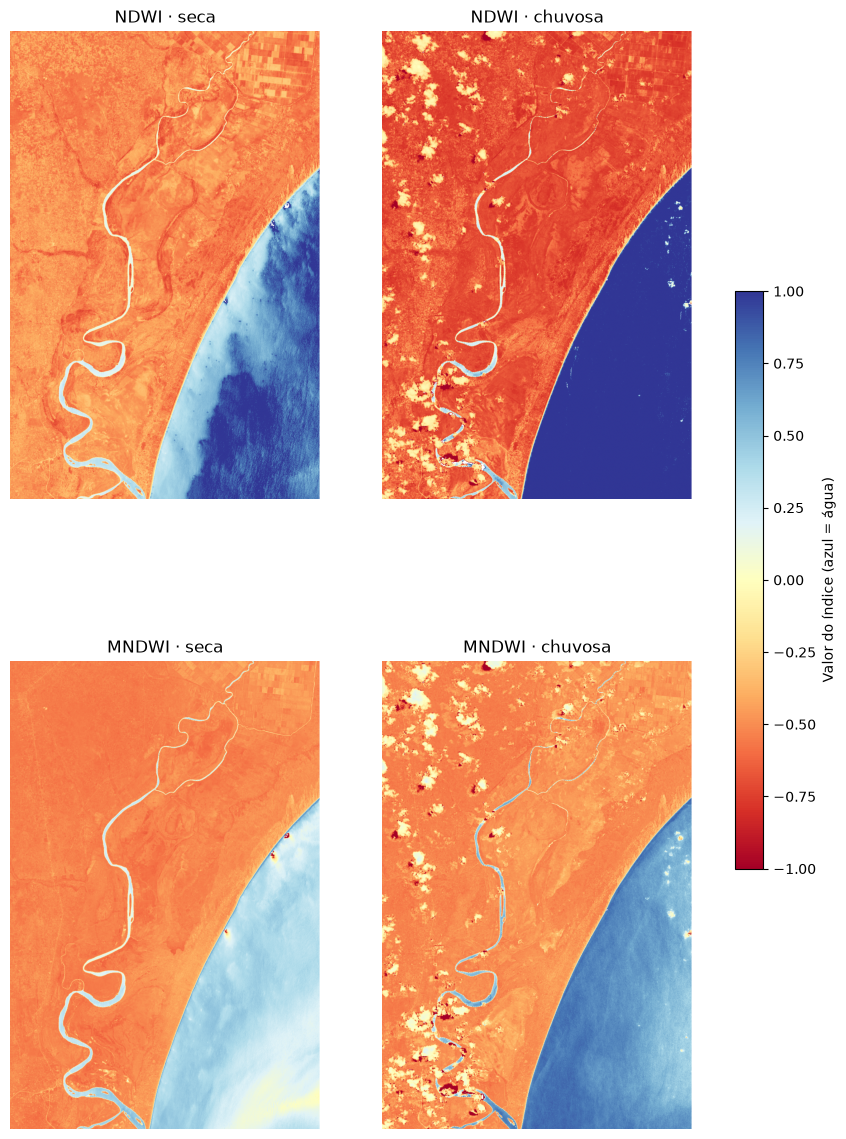

In [8]:
preenchido(mndwi_seca, mndwi_chuvosa)
fig, eixos = plt.subplots(2, 2, figsize=(11, 15))
mapas = [(ndwi_seca, "NDWI · seca"), (ndwi_chuvosa, "NDWI · chuvosa"),
         (mndwi_seca, "MNDWI · seca"), (mndwi_chuvosa, "MNDWI · chuvosa")]
for eixo, (indice, titulo) in zip(eixos.ravel(), mapas):
    figura = eixo.imshow(indice, cmap="RdYlBu", vmin=-1, vmax=1)
    eixo.set_title(titulo)
    eixo.axis("off")
fig.colorbar(figura, ax=eixos, shrink=0.5, label="Valor do índice (azul = água)")
plt.show()

✍️ **Pergunta:** o NDWI e o MNDWI mostram a mesma água? Onde diferem?

**Resposta-modelo (facilitadores):** Nos anos sem problemas especiais, os dois índices mostram quase a mesma água; o MNDWI separa melhor a água da vila e do solo escuro.

## Passo 4 · Limiar e área ✏️

Primeiro o histograma do MNDWI na estação chuvosa (só zona e sem nuvens). Depois conte a água.
Use **LIMIAR = 0** para verificar as respostas; no Passo 6 pode escolher o seu limiar.

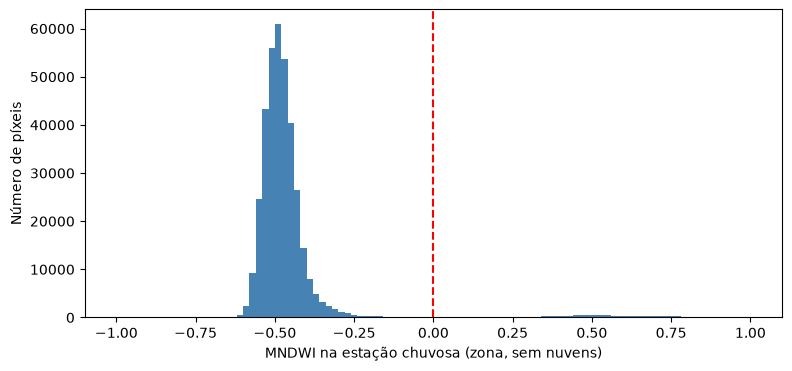

In [9]:
preenchido(mndwi_chuvosa)
vistos = zona & ~chuvosa["nuvem"]
plt.figure(figsize=(9, 4))
plt.hist(mndwi_chuvosa[vistos], bins=100, range=(-1, 1), color="steelblue")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("MNDWI na estação chuvosa (zona, sem nuvens)")
plt.ylabel("Número de píxeis")
plt.show()

In [10]:
LIMIAR = 0.0

agua_seca    = (mndwi_seca > LIMIAR) & zona & ~seca["nuvem"]
agua_chuvosa = (mndwi_chuvosa > LIMIAR) & zona & ~chuvosa["nuvem"]
valido = zona & ~seca["nuvem"] & ~chuvosa["nuvem"]                      # vistos nas duas datas
nova = (mndwi_chuvosa > LIMIAR) & ~(mndwi_seca > LIMIAR) & valido      # água que não estava lá antes

# ✏️ Conte os píxeis de cada mapa (.sum()) e multiplique pela área de um píxel
ha_seca    = agua_seca.sum() * area_pixel_ha
ha_chuvosa = agua_chuvosa.sum() * area_pixel_ha
ha_nova    = nova.sum() * area_pixel_ha

if LIMIAR == 0:
    verificar("agua_seca_ha", ha_seca)
    verificar("agua_chuvosa_ha", ha_chuvosa)
    verificar("agua_nova_ha", ha_nova)
else:
    print("A verificação só funciona com LIMIAR = 0.")

✅ Certo! agua_seca_ha = 1218.96
✅ Certo! agua_chuvosa_ha = 887.49
✅ Certo! agua_nova_ha = 43.02


In [11]:
preenchido(ha_nova, nuvem_pct)
print(f"Água nova: {ha_nova:.0f} ha = {ha_nova / 100:.1f} km² = cerca de {ha_nova / 0.714:.0f} campos de futebol")
print(f"Atenção: {nuvem_pct:.0f}% da zona tem nuvens. Debaixo delas não sabemos.")

Água nova: 43 ha = 0.4 km² = cerca de 60 campos de futebol
Atenção: 17% da zona tem nuvens. Debaixo delas não sabemos.


✍️ **Pergunta:** o resultado confirma a sua previsão do Passo 1? Porquê?

**Resposta-modelo (facilitadores):** Água nova (MNDWI > 0): cerca de 43 ha. Não houve cheia: só cerca de 43 ha de água nova, espalhados em manchas pequenas. Parte é ruído: sombras de nuvens (17% de nuvens) parecem água escura, e pequenas lagoas enchem com a chuva local.

## Passo 5 · Investigar um píxel do rio ▶️

Escolhemos um píxel do rio (linha 1059, coluna 263) que se vê nas duas datas.
A célula mostra as reflectâncias e os índices nesse píxel. É aqui que se descobrem as "armadilhas".

In [12]:
lin, col = 1059, 263
print(f"{'':10s}{'verde':>8s}{'nir':>8s}{'swir':>8s}{'NDWI':>8s}{'MNDWI':>8s}")
for nome, img in [("seca", seca), ("chuvosa", chuvosa)]:
    g, n, s = img["verde"][lin, col], img["nir"][lin, col], img["swir"][lin, col]
    print(f"{nome:10s}{g:8.3f}{n:8.3f}{s:8.3f}{(g - n) / (g + n):8.2f}{(g - s) / (g + s):8.2f}")

             verde     nir    swir    NDWI   MNDWI
seca         0.060   0.034   0.022    0.28    0.46
chuvosa      0.026   0.011   0.005    0.42    0.68


✍️ **Pergunta:** o píxel é água nas duas datas, segundo cada índice? O que mudou nas bandas?

**Resposta-modelo (facilitadores):** No píxel do rio, na estação chuvosa: verde 0,026, NIR 0,011, SWIR 0,005. Ver o desafio.

## Passo 6 · O vosso mapa final ✏️

Escolham o índice e o limiar, escrevam a justificação e corram. O mapa fica guardado num ficheiro PNG.
A última linha é o vosso resultado para o **quadro da turma**.

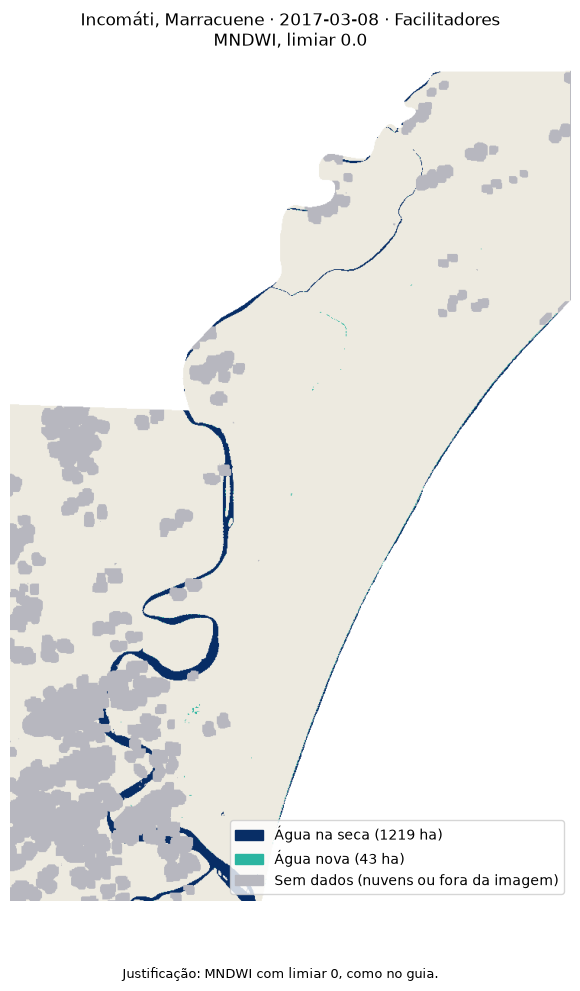

Mapa guardado: mapa_2017_Facilitadores.png
QUADRO DA TURMA -> ano 2017 | MNDWI > 0.0 | água nova 43 ha | nuvens 17%


In [13]:
NOME_PAR = "Facilitadores"       # ✏️ o nome do par
INDICE_FINAL = "MNDWI"                 # ✏️ "MNDWI" ou "NDWI"
LIMIAR_FINAL = 0.0                     # ✏️ o vosso limiar
JUSTIFICACAO = "MNDWI com limiar 0, como no guia."   # ✏️

preenchido(mndwi_seca, mndwi_chuvosa, area_pixel_ha)
indices = {"MNDWI": (mndwi_seca, mndwi_chuvosa), "NDWI": (ndwi_seca, ndwi_chuvosa)}
ind_seca, ind_chuv = indices[INDICE_FINAL]
a_seca = (ind_seca > LIMIAR_FINAL) & zona & ~seca["nuvem"]
a_nova = (ind_chuv > LIMIAR_FINAL) & ~(ind_seca > LIMIAR_FINAL) & valido
ha_s, ha_n = a_seca.sum() * area_pixel_ha, a_nova.sum() * area_pixel_ha

mapa = np.ones(zona.shape + (3,))
mapa[zona] = [0.93, 0.92, 0.88]                                       # zona: bege
mapa[a_seca] = [0.03, 0.18, 0.40]                                     # água antes: azul escuro
mapa[a_nova] = [0.17, 0.71, 0.63]                                     # água nova: verde-água
mapa[zona & (seca["nuvem"] | chuvosa["nuvem"])] = [0.72, 0.72, 0.75]  # sem dados: cinzento

from matplotlib.patches import Patch
legenda = [Patch(color=[0.03, 0.18, 0.40], label=f"Água na seca ({ha_s:.0f} ha)"),
           Patch(color=[0.17, 0.71, 0.63], label=f"Água nova ({ha_n:.0f} ha)"),
           Patch(color=[0.72, 0.72, 0.75], label="Sem dados (nuvens ou fora da imagem)")]
plt.figure(figsize=(8, 11))
plt.imshow(mapa)
plt.legend(handles=legenda, loc="lower right")
plt.title(f"Incomáti, Marracuene · {chuvosa['data']} · {NOME_PAR}\n{INDICE_FINAL}, limiar {LIMIAR_FINAL}")
plt.figtext(0.5, 0.04, "Justificação: " + JUSTIFICACAO, ha="center", fontsize=9, wrap=True)
plt.axis("off")
ficheiro = f"mapa_2017_" + NOME_PAR.replace(" ", "_").replace("?", "") + ".png"
plt.savefig(ficheiro, dpi=150, bbox_inches="tight")
plt.show()
print("Mapa guardado:", ficheiro)
print(f"QUADRO DA TURMA -> ano 2017 | {INDICE_FINAL} > {LIMIAR_FINAL} | água nova {ha_n:.0f} ha | nuvens {100 * chuvosa['nuvem'][zona].mean():.0f}%")
try:
    from google.colab import files
    files.download(ficheiro)
except ImportError:
    pass

## Passo 7 · Conclusões e desafio ✍️

**Conclusões (3 frases):** quanta água nova houve? Confirmou a previsão? Quanto confia no resultado (nuvens, data)?

**Desafio ★:** O caudal nunca passou o limite laranja. Esperava encontrar uma cheia? O que diz o seu mapa? Que parte da "água nova" pode ser erro? Procure-a no mapa e compare com as nuvens.

**Resposta-modelo (facilitadores):** Não houve cheia: só cerca de 43 ha de água nova, espalhados em manchas pequenas. Parte é ruído: sombras de nuvens (17% de nuvens) parecem água escura, e pequenas lagoas enchem com a chuva local.

## Se aparecer um erro

Leia **a última linha** da mensagem vermelha. Quase sempre é um destes:

| Última linha do erro | O que quer dizer | O que fazer |
| --- | --- | --- |
| `NameError: name 'np' is not defined` | Saltou a Célula 0 | Corra a Célula 0 e depois as outras, por ordem |
| `NameError: name 'seca' is not defined` | Saltou a célula que carrega os dados | Corra as células por ordem, de cima para baixo |
| `AssertionError: ✏️ Volte à célula anterior...` | Ficaram `...` por preencher | Complete a célula ✏️ anterior |
| `FileNotFoundError: Não encontrei ...npz` | O ficheiro de dados não está ao lado do notebook | Ponha a pasta `dados` ao lado do notebook, ou carregue o ficheiro quando o Colab pedir |
| `SyntaxError` | Falta um parêntese, uma aspa ou uma vírgula | Compare a sua linha com o exemplo logo acima |
| `IndentationError` | Os espaços no início da linha estão errados | Use 4 espaços dentro de `if`, `for` e `def` |

Se nada resultar: menu **Ambiente de execução → Reiniciar e executar tudo** (Colab) ou **Kernel → Restart & Run All** (Jupyter).